# Deep Learning: Image Classification (Monkeypox)

Import Tools

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import load_img, img_to_array
from PIL import Image

from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

Set style and seed

In [2]:
sns.set_style('whitegrid')
np.random.seed(42)
tf.random.set_seed(42)

Data Import

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nafin59/monkeypox-skin-lesion-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'monkeypox-skin-lesion-dataset' dataset.
Path to dataset files: /kaggle/input/monkeypox-skin-lesion-dataset


In [4]:
print("Dataset folder:")

for folder in os.listdir(path):
    print(folder)

Dataset folder:
Fold1
Augmented Images
Original Images
Monkeypox_Dataset_metadata.csv


Change direktory to Original Images, because we want to preprocess the images manual

# A. Data Understanding

In [18]:
original_path = os.path.join(path, "Original Images", "Original Images")

for folder in os.listdir(original_path):
    folder_path = os.path.join(original_path, folder)
    if os.path.isdir(folder_path):
        print(folder, len(os.listdir(folder_path)))

Others 126
Monkey Pox 102


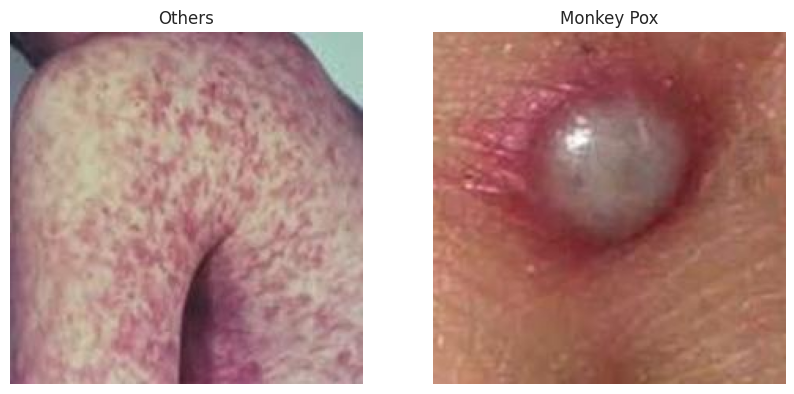

In [26]:
classes = [f for f in os.listdir(original_path)
           if os.path.isdir(os.path.join(original_path, f))]

fig, axes = plt.subplots(1, len(classes), figsize=(5 * len(classes), 5))
for ax, cls in zip(axes, classes):
    cls_path = os.path.join(original_path, cls)
    img_name = os.listdir(cls_path)[0]
    ax.imshow(Image.open(os.path.join(cls_path, img_name)))
    ax.set_title(cls)
    ax.axis("off")
plt.show()

# B. Data Preparation

Train test split

In [7]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    original_path,
    validation_split=0.3,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

val_test_ds = tf.keras.utils.image_dataset_from_directory(
    original_path,
    validation_split=0.3,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

n = tf.data.experimental.cardinality(val_test_ds).numpy()
val_ds = val_test_ds.take(n // 2)
test_ds = val_test_ds.skip(n // 2)

class_names = train_ds.class_names
print(class_names)

Found 228 files belonging to 2 classes.
Using 160 files for training.
Found 228 files belonging to 2 classes.
Using 68 files for validation.
['Monkey Pox', 'Others']


In [8]:
from tensorflow.keras import layers

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

train_ds = train_ds.map(lambda x, y: (augment(x, training=True), y))

# C. Modeling

In [9]:
base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet"
)
base.trainable = False

model = tf.keras.Sequential([
    layers.Rescaling(1./127.5, offset=-1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(train_ds, validation_data=val_ds, epochs=10)
model.evaluate(test_ds)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.4750 - loss: 1.0636 - val_accuracy: 0.7812 - val_loss: 0.6612
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 369ms/step - accuracy: 0.5312 - loss: 0.8981 - val_accuracy: 0.6875 - val_loss: 0.6118
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 373ms/step - accuracy: 0.6500 - loss: 0.7479 - val_accuracy: 0.8750 - val_loss: 0.3511
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 372ms/step - accuracy: 0.6938 - loss: 0.6237 - val_accuracy: 0.7812 - val_loss: 0.4623
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 374ms/step - accuracy: 0.7437 - loss: 0.5685 - val_accuracy: 0.8125 - val_loss: 0.4699
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 371ms/step - accuracy: 0.7812 - loss: 0.5289 - val_accuracy: 0.8750 - val_loss: 0.4973
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 371ms/step - accuracy: 0.7812 - loss: 0.5179 - val_accuracy: 0.8750 - val_loss: 0.4100
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 370ms/step - accuracy: 0.7688 - 

[0.43809741735458374, 0.8611111044883728]

# D. Evaluation

In [ ]:

img_path = os.path.join(original_path, class_names[0], os.listdir(os.path.join(original_path, class_names[0]))[0])


img = load_img(img_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # (1, 224, 224, 3)

pred = model.predict(img_array)
idx = np.argmax(pred[0])

print("Prediction :", class_names[idx])
print("Confidence:", f"{pred[0][idx]*100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Prediction : Others
Confidence: 87.38%


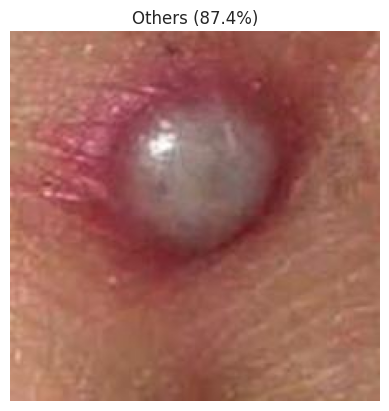

In [12]:
plt.imshow(img)
plt.title(f"{class_names[idx]} ({pred[0][idx]*100:.1f}%)")
plt.axis("off")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step


<>:10: SyntaxWarning: invalid escape sequence '\A'
<>:10: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_2316/1708179656.py:10: SyntaxWarning: invalid escape sequence '\A'
  ax.set_title(f"Pred: {pred_label}\Actual: {true_label}", color=color)


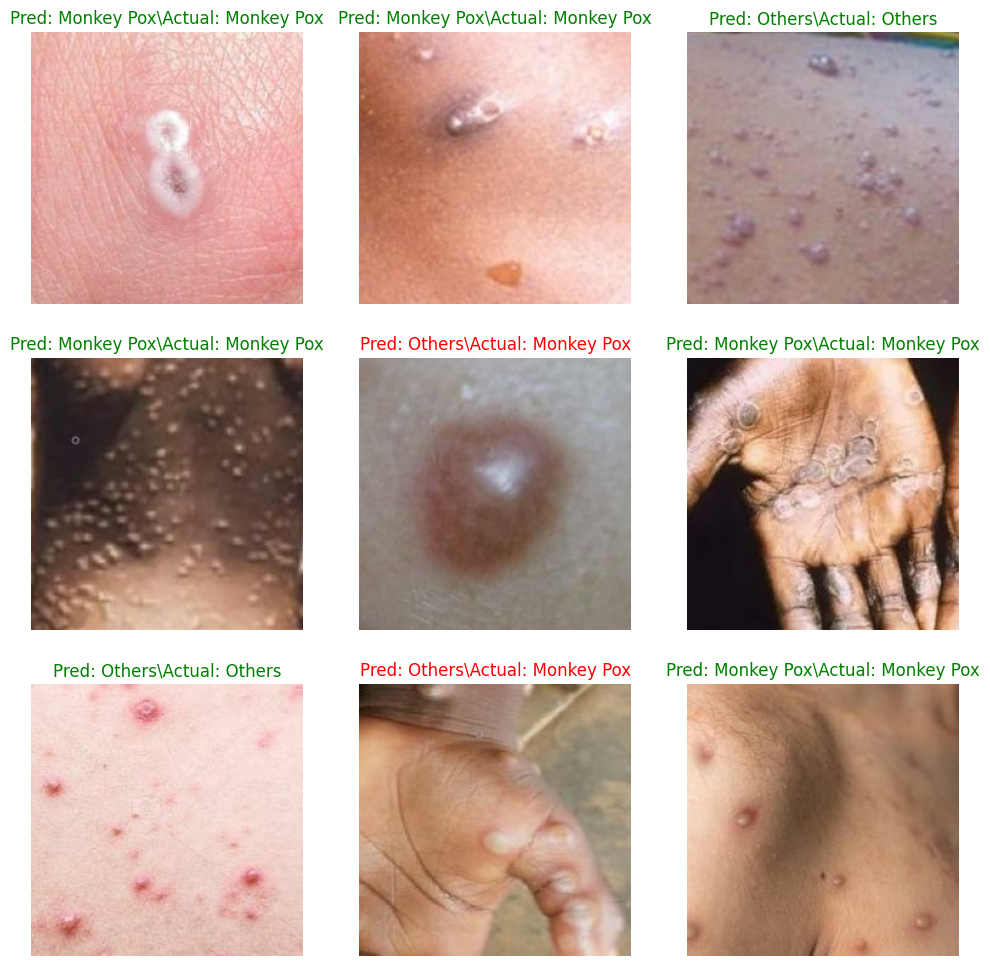

In [15]:
plt.figure(figsize=(12, 12))
for images, labels in test_ds.take(1):
    preds = model.predict(images)
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        pred_label = class_names[np.argmax(preds[i])]
        true_label = class_names[labels[i]]
        color = "green" if pred_label == true_label else "red"
        ax.set_title(f"Pred: {pred_label}\Actual: {true_label}", color=color)
        ax.axis("off")
plt.show()

              precision    recall  f1-score   support

  Monkey Pox       0.88      0.88      0.88        16
      Others       0.90      0.90      0.90        20

    accuracy                           0.89        36
   macro avg       0.89      0.89      0.89        36
weighted avg       0.89      0.89      0.89        36



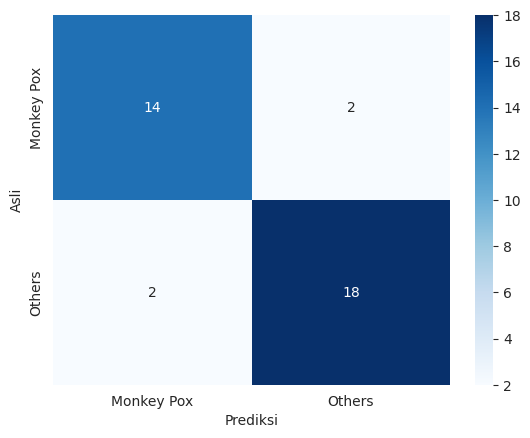

In [14]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true, y_pred = [], []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi")
plt.ylabel("Asli")
plt.show()